**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: -----Brayan Ortega Armendáriz--------------
*   MATRÍCULA: ----A01561888--------------------------

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [3]:
%pip install scikit-learn

  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 2.6 MB/s  0:00:03m0:00:0100:01
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scikit-learn] [scikit-learn]
Note: you may need to restart the kernel to use updated packages.


In [4]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [6]:
# 1. Cargar todos los registros del archivo
cardio_df = pd.read_csv("heart_disease.csv")


# 1.1 Primero onvertir la columna id en el índice del DataFrame
cardio_df = cardio_df.set_index("id")


# 2 Ahora Obtener el resumen de columnas y tipos de datos
cardio_df.info()

columnasNumericas = cardio_df.select_dtypes(
    include="number"
).columns.tolist()

columnasTexto = cardio_df.select_dtypes(
    include="str"
).columns.tolist()

print("\nCantidad de columnas numéricas:", len(columnasNumericas))
print("Columnas numéricas:", columnasNumericas)

print("\nCantidad de columnas de texto:", len(columnasTexto))
print("Columnas de texto:", columnasTexto)


# 3 Aqui es determinar la cantidad de valores únicos por columna
valoresUnicosPorColumna = cardio_df.nunique()

print("\nCantidad de valores únicos por columna:")
print(valoresUnicosPorColumna)

<class 'pandas.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    str    
 2   origin    918 non-null    str    
 3   cp        918 non-null    str    
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    str    
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    str    
 12  ca        309 non-null    float64
 13  thal      434 non-null    str    
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(2), str(6)
memory usage: 114.8+ KB

Cantidad de columnas numéricas: 7
Columnas numéricas: ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'num']

Cantidad de columnas de texto: 6
Columnas de texto: ['sex'

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [7]:
# 2. Problema numero 2

columnasNumericas = cardio_df.select_dtypes(
    include="number"
).columns.tolist()

resumenValoresUnicos = pd.DataFrame({
    "tipo_dato": cardio_df[columnasNumericas].dtypes,
    "cantidad_valores_unicos": cardio_df[columnasNumericas].nunique()
}).sort_values("cantidad_valores_unicos")

print("Variables numéricas ordenadas por cantidad de valores únicos:")
display(resumenValoresUnicos)


# Mostrar los valores de las variables numéricas con 10 o menos valores únicos
candidatasCategoricas = resumenValoresUnicos[
    resumenValoresUnicos["cantidad_valores_unicos"] <= 10
].index

for columna in candidatasCategoricas:
    valores = sorted(cardio_df[columna].dropna().unique())

    print(f"\n{columna}:")
    print(valores)


# Convertir num en una variable categórica ordinal
ordenEnfermedad = pd.CategoricalDtype(
    categories=[0, 1, 2, 3, 4],
    ordered=True
)

cardio_df["num"] = cardio_df["num"].astype(ordenEnfermedad)

print("\nTipo de dato de num después de la conversión:")
print(cardio_df["num"].dtype)

Variables numéricas ordenadas por cantidad de valores únicos:


,tipo_dato,cantidad_valores_unicos
ca,float64,4
num,int64,5
age,int64,50
oldpeak,float64,53
trestbps,float64,60
thalch,float64,119
chol,float64,216



ca:
[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]

num:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Tipo de dato de num después de la conversión:
category


Las variables numéricas con pocos valores únicos fueron ca y num. La variable ca se conservó como numérica discreta ya que esta representa una cantidad: el número de vasos coloreados. Por el otro lado, num es una una variable categórica ordinal, ya que sus valores representan categorías ordenadas: 0 no hay enfermidad los valores de 1 a 4 indican distintos grados de enfermedad cardíaca.

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [9]:
# Problema 3

columnasNumericas = cardio_df.select_dtypes(
    include="number"
).columns.tolist()

columnasCategoricas = cardio_df.select_dtypes(
    include=["str", "category"]
).columns.tolist()


# 1 Estadísticas descriptivas de las variables numéricas

estadisticasNumericas = cardio_df[
    columnasNumericas
].describe().T

estadisticasNumericas["sesgo"] = cardio_df[
    columnasNumericas
].skew()

estadisticasNumericas["curtosis"] = cardio_df[
    columnasNumericas
].kurt()

print("Estadísticas descriptivas de las variables numéricas:")
display(estadisticasNumericas)


# 2 Estadísticas descriptivas de las variables categóricas

estadisticasCategoricas = cardio_df[
    columnasCategoricas
].describe().T

print("Estadísticas descriptivas de las variables categóricas:")
display(estadisticasCategoricas)


# 3 Tablas de frecuencia de cada variable categórica

for columna in columnasCategoricas:

    tablaFrecuencias = (
        cardio_df[columna]
        .value_counts(dropna=False)
        .rename_axis("categoria")
        .reset_index(name="frecuencia")
    )

    tablaFrecuencias["porcentaje"] = (
        tablaFrecuencias["frecuencia"]
        / len(cardio_df)
        * 100
    ).round(2)

    print(f"\nTabla de frecuencias de {columna}:")
    display(tablaFrecuencias)

Estadísticas descriptivas de las variables numéricas:


,count,mean,std,min,25%,50%,75%,max,sesgo,curtosis
age,918.0,53.530501,9.412783,28.0,47.0,54.0,60.0,77.0,-0.193710,-0.382511
trestbps,859.0,132.294529,18.535875,80.0,120.0,130.0,140.0,200.0,0.630411,0.632992
chol,888.0,242.189189,53.424806,85.0,216.0,223.0,268.0,603.0,1.640672,6.573848
thalch,863.0,137.528389,25.950226,60.0,120.0,140.0,157.0,202.0,-0.209319,-0.483939
oldpeak,856.0,0.880607,1.091840,-2.6,0.0,0.5,1.5,6.2,1.037990,1.119834
ca,309.0,0.676375,0.935653,0.0,0.0,0.0,1.0,3.0,1.165978,0.199498


Estadísticas descriptivas de las variables categóricas:


,count,unique,top,freq
sex,918,2,Male,724
origin,918,4,Cleveland,304
cp,918,4,asymptomatic,495
restecg,918,3,normal,551
slope,610,3,flat,345
thal,434,3,normal,196
num,918,5,0,411



Tabla de frecuencias de sex:


...

,categoria,frecuencia,porcentaje
0,flat,345,37.58
1,NaN,308,33.55
2,upsloping,202,22.00
3,downsloping,63,6.86



Tabla de frecuencias de thal:


,categoria,frecuencia,porcentaje
0,NaN,484,52.72
1,normal,196,21.35
2,reversable defect,192,20.92
3,fixed defect,46,5.01



Tabla de frecuencias de num:


,categoria,frecuencia,porcentaje
0,0,411,44.77
1,1,263,28.65
2,2,109,11.87
3,3,107,11.66
4,4,28,3.05


4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

Valores faltantes por columna:


,cantidad_faltantes,porcentaje_faltantes
fbs,89,9.69
oldpeak,62,6.75
trestbps,59,6.43
thalch,55,5.99
exang,55,5.99
chol,30,3.27
age,0,0.00
sex,0,0.00
origin,0,0.00
cp,0,0.00


Columnas eliminadas: []


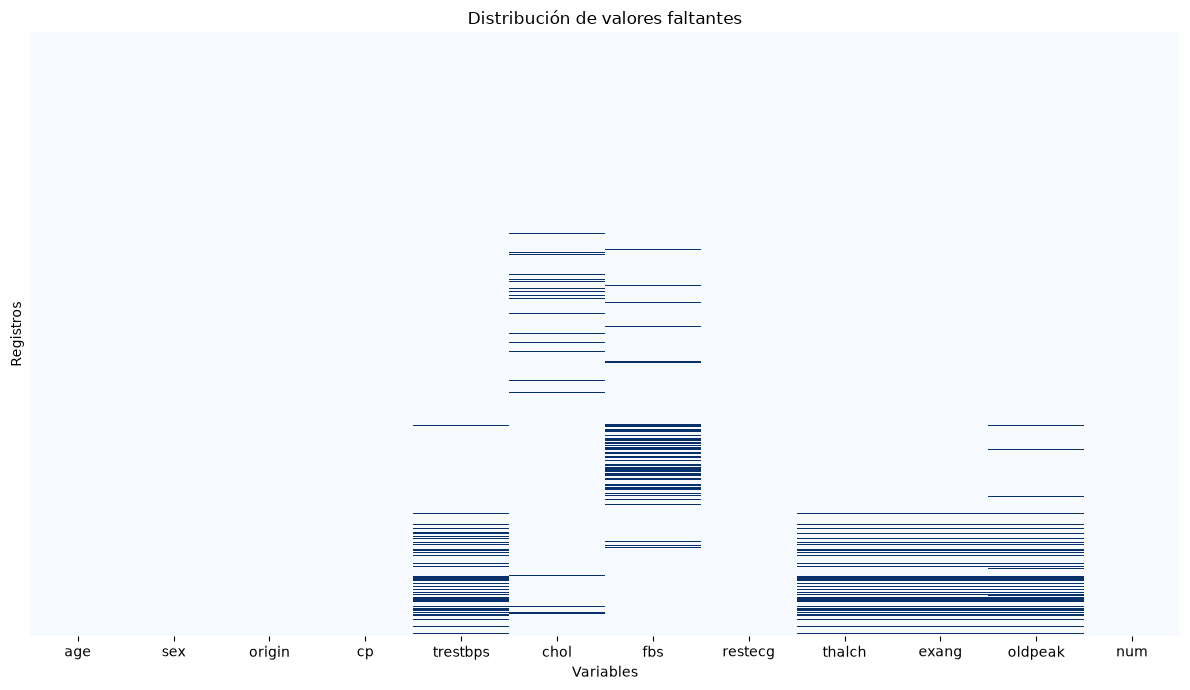

Cantidad de filas con dos o más valores faltantes:
59

Combinaciones de variables faltantes simultáneamente:


,cantidad
"(trestbps, thalch, exang, oldpeak)",51
"(fbs, oldpeak)",3
"(trestbps, chol, thalch, exang, oldpeak)",3
"(trestbps, thalch, exang)",1
"(trestbps, fbs, oldpeak)",1


In [13]:
# Problema 4, calcular cantidad y porcentaje de valores faltantes

resumenFaltantes = pd.DataFrame({
    "cantidad_faltantes": cardio_df.isna().sum(),
    "porcentaje_faltantes": cardio_df.isna().mean() * 100
}).sort_values(
    "porcentaje_faltantes",
    ascending=False
)

resumenFaltantes["porcentaje_faltantes"] = (
    resumenFaltantes["porcentaje_faltantes"].round(2)
)

print("Valores faltantes por columna:")
display(resumenFaltantes)


# 2 Ahora eliminar columnas con más de 30% de valores faltantes

columnasEliminar = resumenFaltantes[
    resumenFaltantes["porcentaje_faltantes"] > 30
].index.tolist()

print("Columnas eliminadas:", columnasEliminar)

cardio_df = cardio_df.drop(
    columns=columnasEliminar
)


#3 Toca crear el mapa de calor de las columnas restantes

plt.figure(figsize=(12, 7))

sns.heatmap(
    cardio_df.isna(),
    yticklabels=False,
    cbar=False,
    cmap="Blues"
)

plt.title("Distribución de valores faltantes")
plt.xlabel("Variables")
plt.ylabel("Registros")
plt.tight_layout()
plt.show()


# 4 Procedo a identificar variables faltantes de manera simultánea

mascaraFaltantes = cardio_df.isna()

filasConFaltantesSimultaneos = (
    mascaraFaltantes.sum(axis=1) >= 2
)

patronesSimultaneos = (
    mascaraFaltantes.loc[filasConFaltantesSimultaneos]
    .apply(
        lambda fila: tuple(fila.index[fila]),
        axis=1
    )
    .value_counts()
)

print("Cantidad de filas con dos o más valores faltantes:")
print(filasConFaltantesSimultaneos.sum())

print("\nCombinaciones de variables faltantes simultáneamente:")
display(
    patronesSimultaneos.rename("cantidad").to_frame()
)

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [20]:
from scipy.stats import ttest_ind


def Diagnose_MV_Numerical(df, str_att_name, BM_MV):

    MV_labels = {
        False: "Without Missing Values",
        True: "With Missing Values"
    }

    # Aquí usamos una lista, porque necesitamos guardar
    # dos series numéricas completas
    datosBoxplot = []
    labels = []

    for poss in [False, True]:

        BM = BM_MV == poss

        datosGrupo = df.loc[
            BM,
            str_att_name
        ].dropna()

        datosBoxplot.append(datosGrupo)
        labels.append(MV_labels[poss])


    # Comparar ambos grupos mediante un boxplot
    plt.boxplot(
        datosBoxplot,
        orientation="horizontal"
    )

    plt.yticks(
        [1, 2],
        labels
    )

    plt.xlabel(str_att_name)
    plt.show()


    # Comparar las distribuciones con histogramas
    plt.figure(figsize=(10, 4))

    att_range = (
        df[str_att_name].min(),
        df[str_att_name].max()
    )

    for i, poss in enumerate([False, True]):

        plt.subplot(1, 2, i + 1)

        BM = BM_MV == poss

        df.loc[
            BM,
            str_att_name
        ].dropna().hist()

        plt.xlim(att_range)
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.tight_layout()
    plt.show()


    # Separar los datos para la prueba de hipótesis
    group_1_data = df.loc[
        BM_MV,
        str_att_name
    ].dropna()

    group_2_data = df.loc[
        ~BM_MV,
        str_att_name
    ].dropna()


    # Prueba t de Welch
    p_value = ttest_ind(
        group_1_data,
        group_2_data,
        equal_var=False
    ).pvalue

    print(
        "p-value of t-test: {}".format(
            p_value
        )
    )

    return p_value

In [21]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

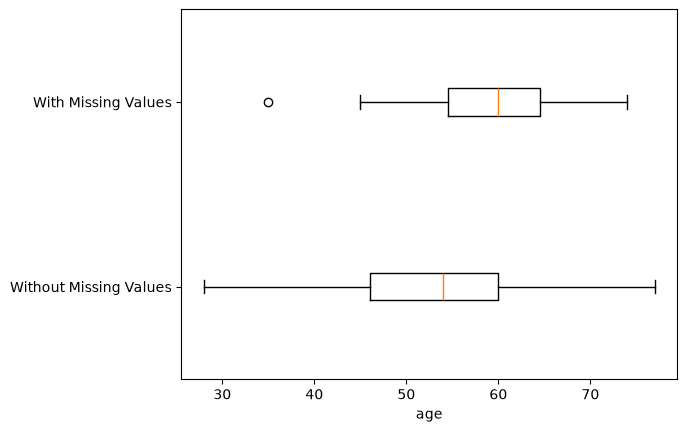

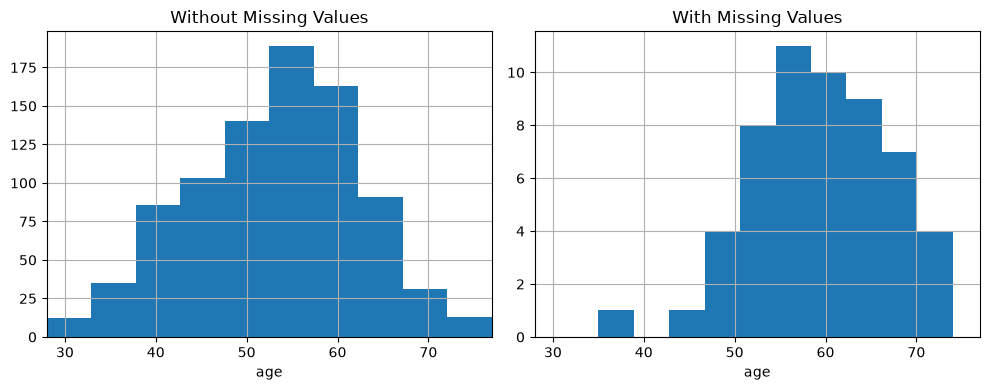

p-value of t-test: 4.115876441882043e-07


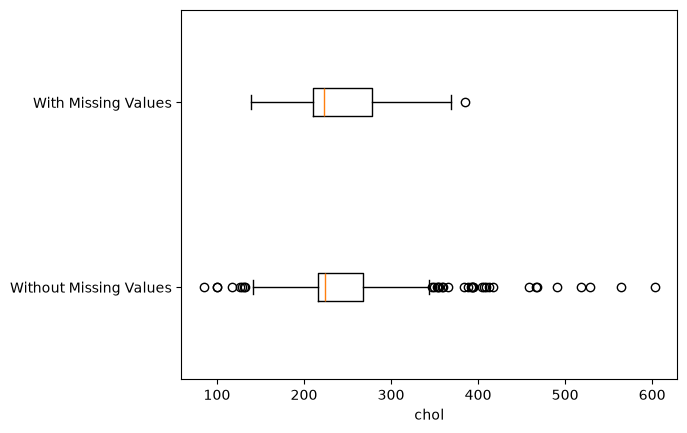

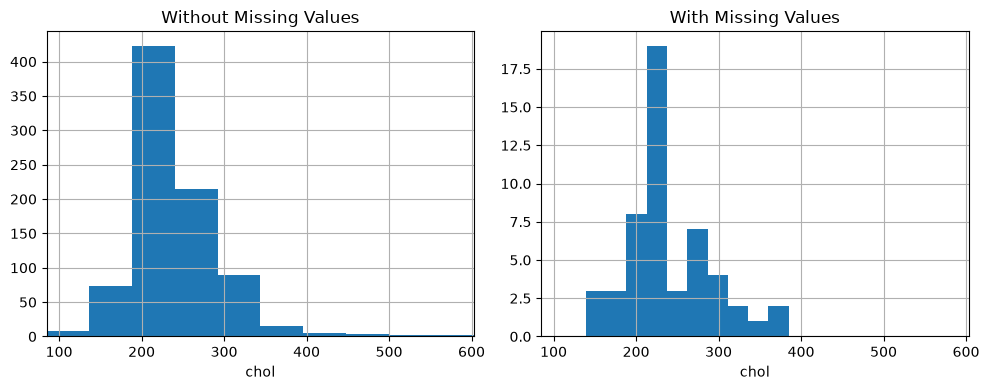

p-value of t-test: 0.7104715640105806


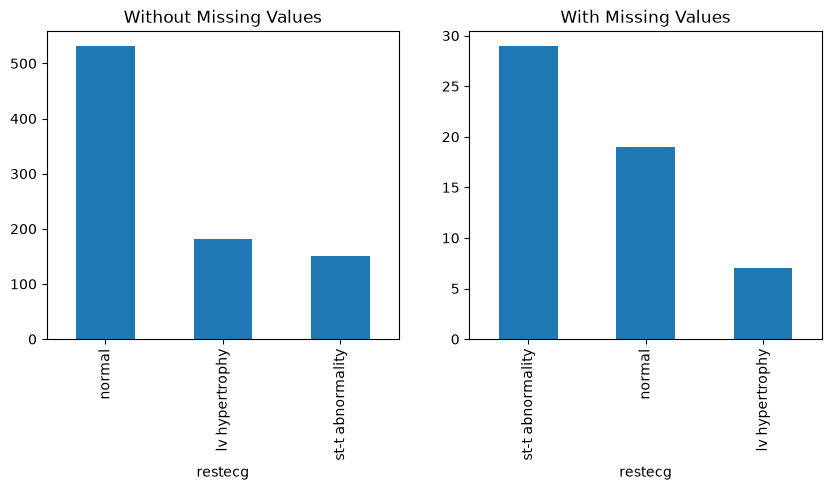

p-value of Chi_squared test: 1.1472889573985467e-09


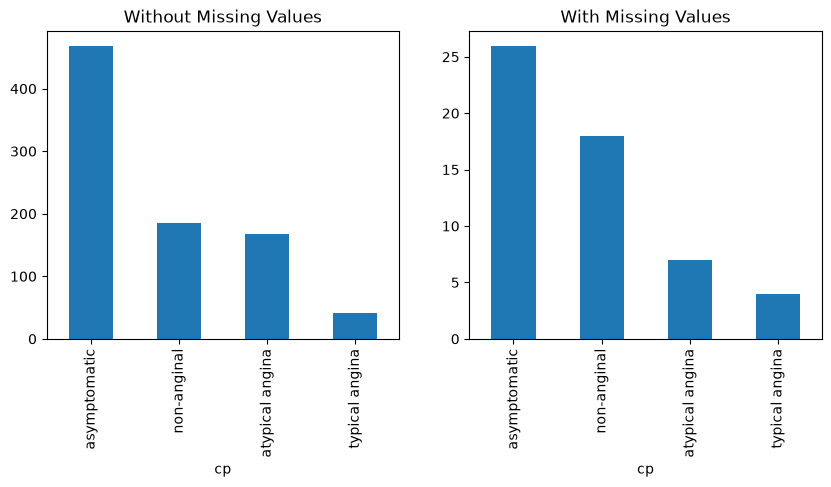

p-value of Chi_squared test: 0.1542009717725172


In [22]:
# Crear la máscara que divide los pacientes
# según la presencia o ausencia de thalch

faltanteThalch = cardio_df["thalch"].isna()


# Comparaciones numéricas

pAge = Diagnose_MV_Numerical(
    cardio_df,
    "age",
    faltanteThalch
)

pChol = Diagnose_MV_Numerical(
    cardio_df,
    "chol",
    faltanteThalch
)


# Comparaciones categóricas

pRestecg = Diagnose_MV_Categorical(
    cardio_df,
    "restecg",
    faltanteThalch
)

pCp = Diagnose_MV_Categorical(
    cardio_df,
    "cp",
    faltanteThalch
)

Los valores faltantes de thalch presentan una relación significativa con age y restecg, pero no con chol ni cp. Por ello, el mecanismo no parece ser MCAR, sino compatible con MAR, ya que la ausencia de thalch depende de otras variables observadas.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

,faltantes_antes,faltantes_despues
thalch,0,0
exang,0,0
oldpeak,0,0


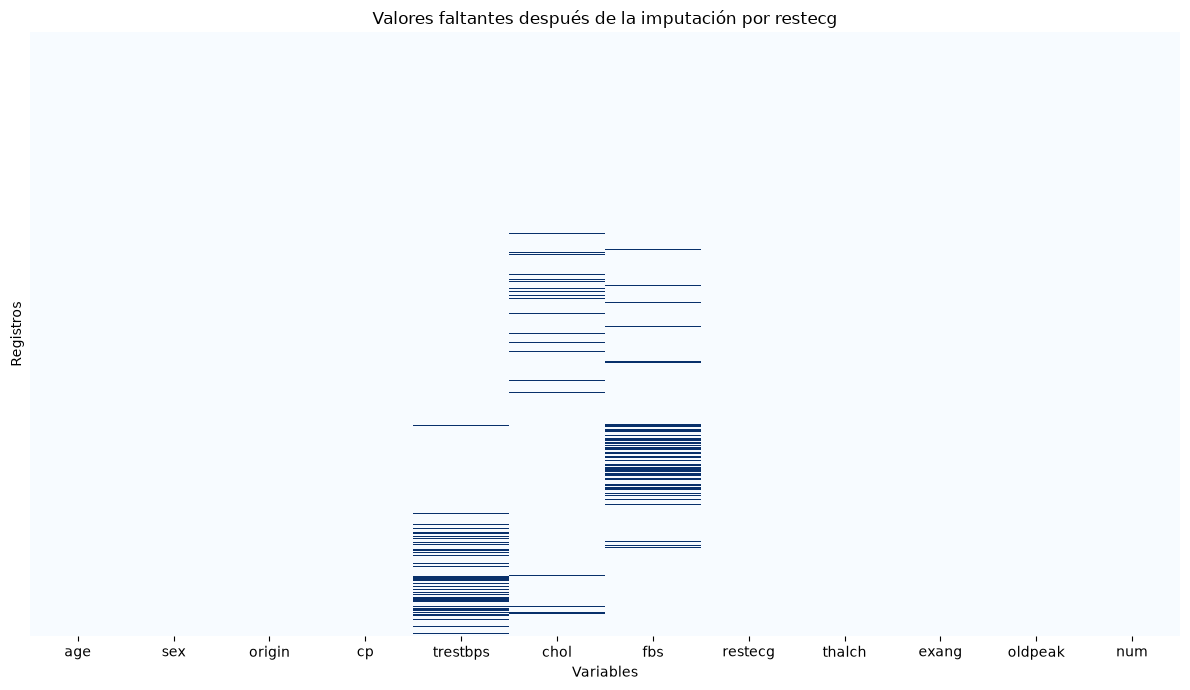

In [27]:
# Problema 6 Variables con un patrón similar de valores faltantes

variablesPatronSimilar = [
    "thalch",
    "exang",
    "oldpeak"
]


# Guardar la cantidad de faltantes antes de imputar

faltantesAntes = cardio_df[
    variablesPatronSimilar
].isna().sum()


# 1 Primuero Imputar las variables numéricas con la mediana
# calculada dentro de cada categoría de restecg

for variable in ["thalch", "oldpeak"]:

    cardio_df[variable] = (
        cardio_df
        .groupby(
            "restecg",
            dropna=False,
            observed=True
        )[variable]
        .transform(
            lambda grupo: grupo.fillna(
                grupo.median()
            )
        )
    )


# 2 Imputar exang con la moda
# calculada dentro de cada categoría de restecg

cardio_df["exang"] = (
    cardio_df
    .groupby(
        "restecg",
        dropna=False,
        observed=True
    )["exang"]
    .transform(
        lambda grupo: grupo.fillna(
            grupo.mode().iloc[0]
        )
    )
)


# Comparar la cantidad de faltantes antes y después

faltantesDespues = cardio_df[
    variablesPatronSimilar
].isna().sum()

comparacionImputacion = pd.DataFrame({
    "faltantes_antes": faltantesAntes,
    "faltantes_despues": faltantesDespues
})

display(comparacionImputacion)


# 3 Generar nuevamente el mapa de calor

plt.figure(figsize=(12, 7))

sns.heatmap(
    cardio_df.isna(),
    yticklabels=False,
    cbar=False,
    cmap="Blues"
)

plt.title("Valores faltantes después de la imputación por restecg")
plt.xlabel("Variables")
plt.ylabel("Registros")
plt.tight_layout()
plt.show()

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [28]:
from sklearn.impute import SimpleImputer

# 1 primero variables que aún tienen valores faltantes
columnasNumericasFaltantes = [
    "trestbps",
    "chol"
]

columnasCategoricasFaltantes = [
    "fbs",
    "restecg"
]

columnasPendientes = (
    columnasNumericasFaltantes
    + columnasCategoricasFaltantes
)

faltantesAntes = cardio_df[
    columnasPendientes
].isna().sum()


# 2. Imputar las variables numéricas con la mediana general
imputadorNumerico = SimpleImputer(
    strategy="median"
)

cardio_df[columnasNumericasFaltantes] = (
    imputadorNumerico.fit_transform(
        cardio_df[columnasNumericasFaltantes]
    )
)


# 3. Imputar las variables categóricas con la categoría más frecuente
imputadorCategorico = SimpleImputer(
    strategy="most_frequent"
)

datosCategoricos = cardio_df[
    columnasCategoricasFaltantes
].astype("object")

cardio_df[columnasCategoricasFaltantes] = (
    imputadorCategorico.fit_transform(
        datosCategoricos
    )
)

# Recuperar su naturaleza de texto/categórica
cardio_df[columnasCategoricasFaltantes] = (
    cardio_df[columnasCategoricasFaltantes]
    .astype("str")
)


# 4. Comprobar el resultado de la imputación
faltantesDespues = cardio_df[
    columnasPendientes
].isna().sum()

comparacionFaltantes = pd.DataFrame({
    "faltantes_antes": faltantesAntes,
    "faltantes_despues": faltantesDespues
})

print("Comparación de valores faltantes:")
print(comparacionFaltantes)

print("\nValores utilizados para imputar:")
print(
    pd.Series(
        list(imputadorNumerico.statistics_)
        + list(imputadorCategorico.statistics_),
        index=columnasPendientes,
        name="valor_imputado"
    )
)

print(
    "\nTotal de valores faltantes en el dataframe:",
    cardio_df.isna().sum().sum()
)

Comparación de valores faltantes:
          faltantes_antes  faltantes_despues
trestbps               59                  0
chol                   30                  0
fbs                    89                  0
restecg                 0                  0

Valores utilizados para imputar:
trestbps     130.0
chol         223.0
fbs          False
restecg     normal
Name: valor_imputado, dtype: object

Total de valores faltantes en el dataframe: 0


### Justificación de cada una de las estrategias

Para trestbps y chol se utilizó la mediana, porque son variables numéricas que pueden contener valores extremos. La mediana no se ve tan afectada por estos valores que la media, especialmente en trestbps, cuyos posibles valores atípicos se analizarán en los ejercicios posteriores.

Para fbs y restecg se utilizó most_frequent, porque estas son de tipo  categóricas. 

Después de la imputación, el dataframe ya no contiene valores faltantes.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

Variables numéricas:
['age', 'trestbps', 'chol', 'thalch', 'oldpeak']


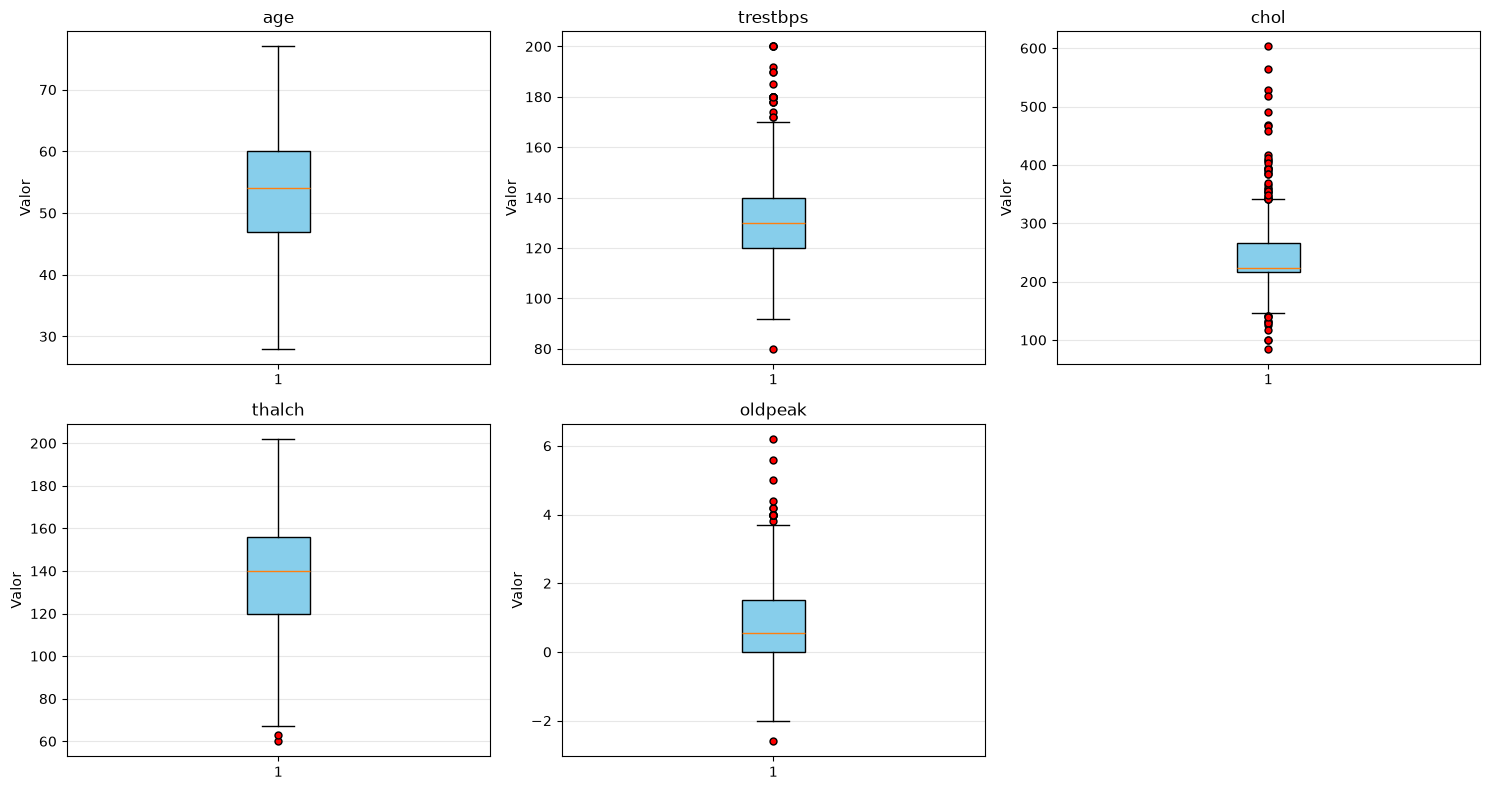

Valores atípicos obtenidos de los boxplots:
variable  valor_atipico
trestbps           80.0
trestbps          172.0
trestbps          180.0
trestbps          200.0
trestbps          174.0
trestbps          178.0
trestbps          192.0
trestbps          180.0
trestbps          178.0
trestbps          180.0
trestbps          190.0
trestbps          180.0
trestbps          180.0
trestbps          180.0
trestbps          180.0
trestbps          200.0
trestbps          180.0
trestbps          180.0
trestbps          180.0
trestbps          200.0
trestbps          185.0
trestbps          200.0
trestbps          180.0
trestbps          178.0
trestbps          172.0
trestbps          180.0
trestbps          190.0
    chol          141.0
    chol          126.0
    chol          131.0
    chol          132.0
    chol          129.0
    chol          100.0
    chol           85.0
    chol          117.0
    chol          100.0
    chol          142.0
    chol          139.0
    chol          35

In [31]:
# Primero hay que identificar las variables que actualmente son numéricas
columnasNumericas = cardio_df.select_dtypes(
    include=["number"]
).columns.tolist()

print("Variables numéricas:")
print(columnasNumericas)


# 2. Preparar la cuadrícula de gráficas
numeroColumnas = 3
numeroFilas = int(
    np.ceil(len(columnasNumericas) / numeroColumnas)
)

fig, axes = plt.subplots(
    numeroFilas,
    numeroColumnas,
    figsize=(15, 4 * numeroFilas)
)

# Convertir los ejes en una lista para recorrerlos fácilmente
axes = np.atleast_1d(axes).ravel()

registrosAtipicos = []


# 3. Dibujar un boxplot y obtener sus valores atípicos
for posicion, columna in enumerate(columnasNumericas):

    resultadoBoxplot = axes[posicion].boxplot(
        cardio_df[columna].dropna(),
        patch_artist=True,
        boxprops={"facecolor": "skyblue"},
        flierprops={
            "marker": "o",
            "markerfacecolor": "red",
            "markersize": 5
        }
    )

    axes[posicion].set_title(columna)
    axes[posicion].set_ylabel("Valor")
    axes[posicion].grid(
        axis="y",
        alpha=0.3
    )

    # "fliers" contiene los puntos dibujados como atípicos
    valoresAtipicos = (
        resultadoBoxplot["fliers"][0].get_ydata()
    )

    # Guardar cada valor atípico y la variable a la que pertenece
    for valor in valoresAtipicos:
        registrosAtipicos.append({
            "variable": columna,
            "valor_atipico": valor
        })


# 4. Ocultar espacios sobrantes de la cuadrícula
for posicionSobrante in range(
    len(columnasNumericas),
    len(axes)
):
    axes[posicionSobrante].set_visible(False)

plt.tight_layout()
plt.show()


# 5. Convertir los valores atípicos obtenidos en un dataframe
atipicos_df = pd.DataFrame(registrosAtipicos)

print("Valores atípicos obtenidos de los boxplots:")
print(atipicos_df.to_string(index=False))

print("\nCantidad de valores atípicos por variable:")
print(
    atipicos_df["variable"]
    .value_counts()
    .rename("cantidad")
)

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [32]:
# 1. Obtener los cuartiles de trestbps
q1Trestbps = cardio_df["trestbps"].quantile(0.25)
q3Trestbps = cardio_df["trestbps"].quantile(0.75)

# El IQR contiene el 50 % central de los datos
iqrTrestbps = q3Trestbps - q1Trestbps


# 2. Calcular los límites para detectar valores atípicos
limiteInferior = q1Trestbps - 1.5 * iqrTrestbps
limiteSuperior = q3Trestbps + 1.5 * iqrTrestbps

print("Primer cuartil (Q1):", q1Trestbps)
print("Tercer cuartil (Q3):", q3Trestbps)
print("Rango intercuartílico (IQR):", iqrTrestbps)
print("Límite inferior:", limiteInferior)
print("Límite superior:", limiteSuperior)


# 3. Filtrar los registros fuera de los límites
mascaraAtipicosTrestbps = (
    (cardio_df["trestbps"] < limiteInferior)
    | (cardio_df["trestbps"] > limiteSuperior)
)

atipicosTrestbpsIQR = cardio_df.loc[
    mascaraAtipicosTrestbps,
    ["trestbps"]
]

print("\nRegistros atípicos de trestbps según el IQR:")
print(atipicosTrestbpsIQR.to_string())

print(
    "\nCantidad de valores atípicos según el IQR:",
    len(atipicosTrestbpsIQR)
)


# 4. Recuperar los valores obtenidos gráficamente en el ejercicio 8
atipicosTrestbpsBoxplot = atipicos_df.loc[
    atipicos_df["variable"] == "trestbps",
    "valor_atipico"
].to_numpy()


# 5. Comparar ambos resultados
valoresIQR = (
    atipicosTrestbpsIQR["trestbps"]
    .to_numpy()
)

resultadosCoinciden = np.array_equal(
    np.sort(valoresIQR),
    np.sort(atipicosTrestbpsBoxplot)
)

print(
    "\nCantidad obtenida mediante el boxplot:",
    len(atipicosTrestbpsBoxplot)
)

print(
    "¿Los valores obtenidos por ambos métodos coinciden?",
    resultadosCoinciden
)

Primer cuartil (Q1): 120.0
Tercer cuartil (Q3): 140.0
Rango intercuartílico (IQR): 20.0
Límite inferior: 90.0
Límite superior: 170.0

Registros atípicos de trestbps según el IQR:
     trestbps
id           
15      172.0
84      180.0
127     200.0
173     174.0
184     178.0
189     192.0
202     180.0
214     178.0
232     180.0
339     190.0
376     180.0
388     180.0
476     180.0
485     180.0
549     200.0
570     180.0
596     180.0
645      80.0
648     180.0
681     200.0
701     185.0
702     200.0
728     180.0
780     178.0
855     172.0
890     180.0
897     190.0

Cantidad de valores atípicos según el IQR: 27

Cantidad obtenida mediante el boxplot: 27
¿Los valores obtenidos por ambos métodos coinciden? True


### Conclusión

Los valores atípicos de trestbps calculados mediante el método del rango intercuartílico coinciden con los puntos identificados gráficamente por el boxplot. Esto sucede porque el boxplot utiliza por defecto límites calculados con 1.5 veces el IQR.

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

Registros antes de eliminar: 918
Registros eliminados: 27
Registros después de eliminar: 891


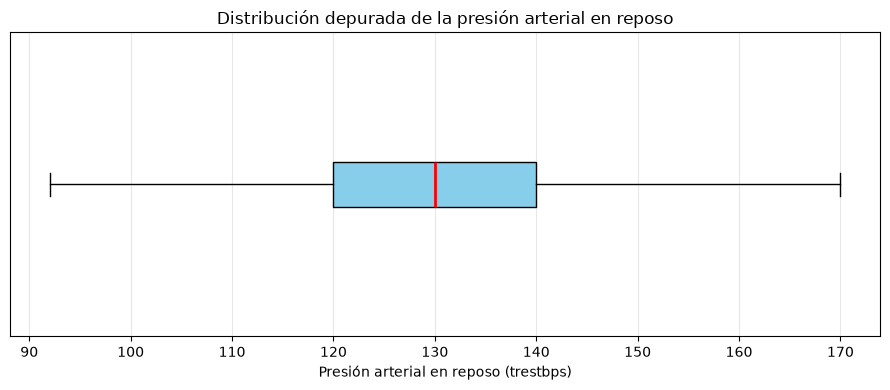

Valores marcados como atípicos en el boxplot final: []


In [33]:
# 1. Guardar la cantidad de registros antes de eliminar
registrosAntes = len(cardio_df)

# Los índices provienen de los valores atípicos identificados
# mediante IQR en el ejercicio 9
indicesAtipicosTrestbps = atipicosTrestbpsIQR.index


# 2. Eliminar del dataframe las filas correspondientes
cardio_df = cardio_df.drop(
    index=indicesAtipicosTrestbps,
    errors="ignore"
).copy()

registrosDespues = len(cardio_df)
registrosEliminados = registrosAntes - registrosDespues

print("Registros antes de eliminar:", registrosAntes)
print("Registros eliminados:", registrosEliminados)
print("Registros después de eliminar:", registrosDespues)


# 3. Dibujar el boxplot final de trestbps
fig, ax = plt.subplots(
    figsize=(9, 4)
)

resultadoBoxplotFinal = ax.boxplot(
    cardio_df["trestbps"],
    orientation="horizontal",
    patch_artist=True,
    boxprops={
        "facecolor": "skyblue"
    },
    medianprops={
        "color": "red",
        "linewidth": 2
    },
    flierprops={
        "marker": "o",
        "markerfacecolor": "orange",
        "markersize": 6
    }
)

ax.set_title(
    "Distribución depurada de la presión arterial en reposo"
)

ax.set_xlabel(
    "Presión arterial en reposo (trestbps)"
)

ax.set_yticks([])
ax.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()
plt.show()


# 4. Revisar los puntos atípicos del boxplot final
atipicosBoxplotFinal = (
    resultadoBoxplotFinal["fliers"][0]
    .get_xdata()
)

print(
    "Valores marcados como atípicos en el boxplot final:",
    atipicosBoxplotFinal
)

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-5.6 SOl, medium)*  Utilizado para explicarme os conceptos, depuerar el código y corregirme ante cada typo que cometiera, resolvíó problemas de versionado de pandas. https://chat.openai.com/

---